Variables
There are 14 attributes in each case of the dataset. They are:
CRIM - per capita crime rate by town
ZN - proportion of residential land zoned for lots over 25,000 sq.ft.
INDUS - proportion of non-retail business acres per town.
CHAS - Charles River dummy variable (1 if tract bounds river; 0 otherwise)
NOX - nitric oxides concentration (parts per 10 million)
RM - average number of rooms per dwelling
AGE - proportion of owner-occupied units built prior to 1940
DIS - weighted distances to five Boston employment centres
RAD - index of accessibility to radial highways
TAX - full-value property-tax rate per $10,000
PTRATIO - pupil-teacher ratio by town
B - 1000(Bk - 0.63)^2 where Bk is the proportion of blacks by town
LSTAT - % lower status of the population
MEDV - Median value of owner-occupied homes in $1000's

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
 

In [5]:
df = pd.read_csv("/Users/ethanbatiuk/Downloads/SYDE572_Assignment2_Boston_Housing.csv")
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33,36.2


In [6]:
#split into train and test then features and targets
train_set = df.iloc[:100].copy()
test_set = df.iloc[100:].copy()
X_train = train_set.drop(columns='MEDV').to_numpy(dtype=float)
y_train = train_set['MEDV'].to_numpy(dtype=float)
X_test = test_set.drop(columns='MEDV').to_numpy(dtype=float)
y_test = test_set['MEDV'].to_numpy(dtype=float)
print(f'Training rows: {len(train_set)}; testing rows: {len(test_set)}') # check that we have first 100 rows for taining

Training rows: 100; testing rows: 406


# Q1 a

In [7]:
def polynomial_design_matrix(X, degree, means=None, scales=None):
    X = np.asarray(X, dtype=float)
    if means is None:
        means = X.mean(axis=0)
    if scales is None:
        scales = X.std(axis=0)
    scales = np.where(scales == 0, 1.0, scales)
    X_scaled = (X - means) / scales
    # Standardize inputs before forming powers to keep higher-degree
    # columns on manageable numeric scales.
    powers = [X_scaled ** p for p in range(1, degree + 1)]
    return np.column_stack([np.ones(X.shape[0]), *powers]), means, scales

def fit_polynomial_regression(X, y, degree):
    Phi, x_means, x_scales = polynomial_design_matrix(X, degree)
    y_mean, y_scale = np.mean(y), np.std(y)
    if y_scale == 0:
        y_scale = 1.0
    y_scaled = (y - y_mean) / y_scale
    weights, *_ = np.linalg.lstsq(Phi, y_scaled, rcond=None)
    return {'weights': weights, 'x_means': x_means, 'x_scales': x_scales,
            'y_mean': y_mean, 'y_scale': y_scale, 'degree': degree}

def predict_polynomial_regression(model, X):
    Phi, _, _ = polynomial_design_matrix(
        X, model['degree'], model['x_means'], model['x_scales'])
    return (Phi @ model['weights']) * model['y_scale'] + model['y_mean']

def rms_error(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

,degree,training_RMS,test_RMS
0,1,2.037,3.644500e+01
1,2,1.578,1.097188e+03
2,3,1.449,4.867282e+04
3,4,1.270,2.185968e+07
4,5,1.097,1.835803e+10
5,6,1.073,5.024089e+12
6,7,0.881,6.879332e+15


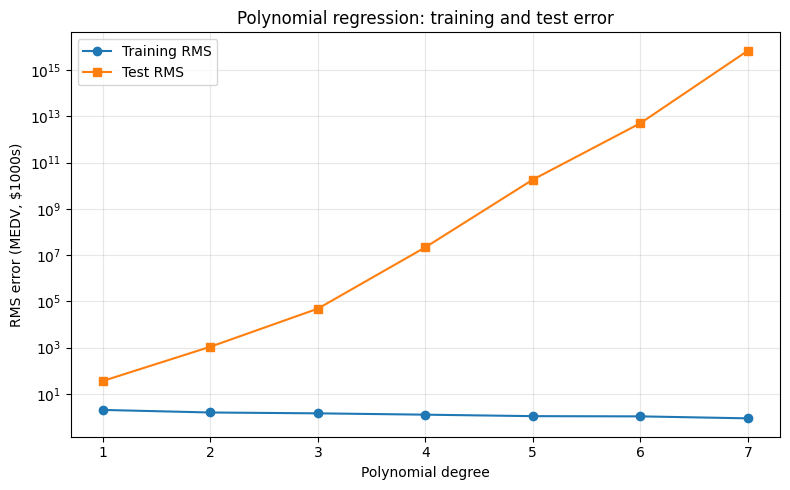

In [8]:
degrees = np.arange(1, 8)
train_rms, test_rms, models = [], [], {}

for degree in degrees:
    model = fit_polynomial_regression(X_train, y_train, degree)
    models[degree] = model
    train_rms.append(rms_error(y_train, predict_polynomial_regression(model, X_train)))
    test_rms.append(rms_error(y_test, predict_polynomial_regression(model, X_test)))

results_a = pd.DataFrame({'degree': degrees, 'training_RMS': train_rms, 'test_RMS': test_rms})
display(results_a.round(3))

plt.figure(figsize=(8, 5))
plt.plot(degrees, train_rms, marker='o', label='Training RMS')
plt.plot(degrees, test_rms, marker='s', label='Test RMS')
plt.xticks(degrees)
plt.yscale("log") # scale so you can see the different polynomial errors
plt.xlabel('Polynomial degree')
plt.ylabel('RMS error (MEDV, $1000s)')
plt.title('Polynomial regression: training and test error')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

The training error decreases as we increase the polynomial degree this is very intuitive because as we increase the power we get more degrees of freedom to fit to our training data making it much easier to fit obscure data. However, this relationship is inversely true for testing error. This is because while our higher order polynomials clearly fit some training data better they have no generalizabillity and have error on the order of quintillion (10^15 * thousands) dollars which is more money than there is on earth making its predictive value incredibly poor. Our linear model actual has the optimal predictive value for this data.

# Q1 b

In [9]:
poly_1 = models[1]
weight_6 = poly_1["weights"][6]
weight_8 = poly_1["weights"][8] #get out the weights
scale6,scale8 = poly_1["x_scales"][5], poly_1["x_scales"][7]# no scale on bias so shift 1 index
print(f"the weights for the 6th input: {weight_6} with inputs divided by {scale6}.\n The weights for input 8: {weight_8} wiht inputs divided by {scale8}")




the weights for the 6th input: 0.7113347873976557 with inputs divided by 0.4883777655667792.
 The weights for input 8: 0.0018167149893591004 wiht inputs divided by 1.4049975245028015


The weights both make sense. weight 6(number of rooms per dwelling) being quite positive makes sense since in general a house with more rooms is worth more and can fit more inhabitants. Input 8(weighted distance to 5 boston employment centers) being positive also makes sense however, it's weight is extrememly small which is reasonable since in my experience, most people pick houses for other amenities first before picking for distance to employment centers (if anyone even looks at this). So while it may have a slight uptick in home prices simply due to proximity to higher money availability the results are not super strong correlation between x8 and the home price. The scale simply makes sure all the model predictions are consistent and are not dominated by inputs with larger absolute values. This is because RMS will give higher predictive power to higher magnitude values. 

# Q1 c

In [ ]:
X_train_C = X_train[:,2]
X_test_C = X_test[:,2]

,degree,training_RMS,test_RMS
0,1,5.239,9.855
1,2,4.353,18.527
2,3,4.352,17.253
3,4,4.254,84.141
4,5,4.227,176.841
5,6,4.214,1009.125
6,7,3.994,29250.497


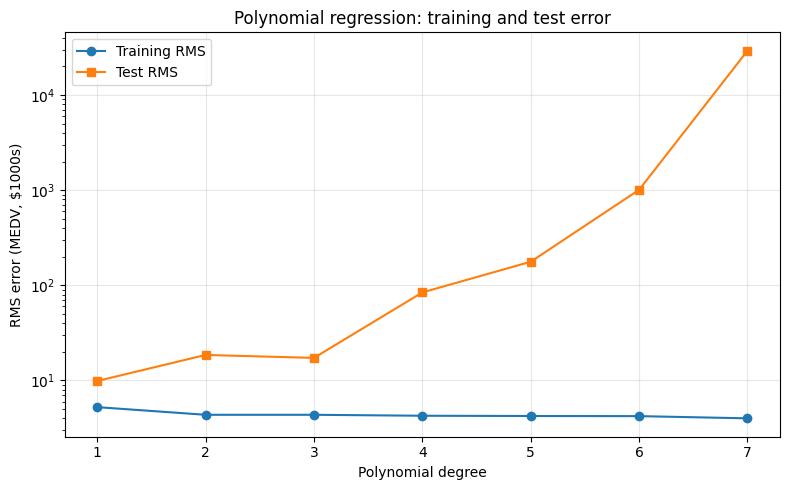

In [ ]:
#reuse code form a using only the 1 input as given in the question
train_rms_c, test_rms_c, models_c = [], [], {}

for degree in degrees:
    model_c = fit_polynomial_regression(X_train_C, y_train, degree)
    models_c[degree] = model_c
    train_rms_c.append(rms_error(y_train, predict_polynomial_regression(model_c, X_train_C)))
    test_rms_c.append(rms_error(y_test, predict_polynomial_regression(model_c, X_test_C)))

results_c = pd.DataFrame({'degree': degrees, 'training_RMS': train_rms_c, 'test_RMS': test_rms_c})
display(results_c.round(3))

plt.figure(figsize=(8, 5))
plt.plot(degrees, train_rms_c, marker='o', label='Training RMS')
plt.plot(degrees, test_rms_c, marker='s', label='Test RMS')
plt.xticks(degrees)
plt.yscale("log") # scale so you can see the different polynomial errors
plt.xlabel('Polynomial degree')
plt.ylabel('RMS error (MEDV, $1000s)')
plt.title('Polynomial regression: training and test error')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

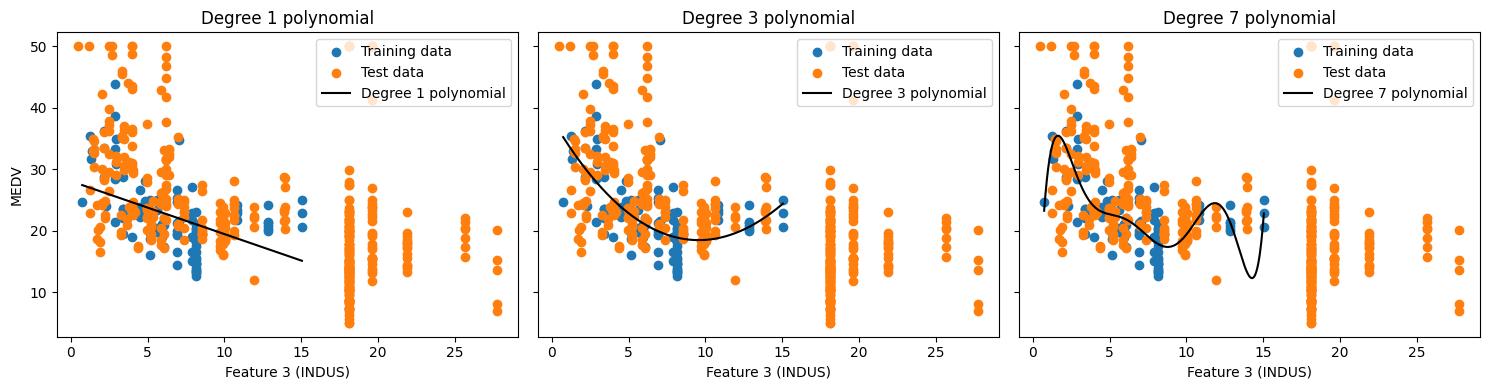

In [ ]:
#now do the visualizations for the function, training data points, test data points.
x_plot = np.linspace(X_train_C.min(), X_train_C.max(), 500) # set bounds to be between the min and max points
fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for i, degree in enumerate([1, 3, 7]):
    model_c = models_c[degree]
    y_plot = predict_polynomial_regression(model_c, x_plot)
    ax[i].scatter(X_train_C, y_train, label='Training data')
    ax[i].scatter(X_test_C, y_test, label='Test data')
    ax[i].plot(x_plot, y_plot, color='black', label=f'Degree {degree} polynomial')
    ax[i].set_xlabel('Feature 3 (INDUS)')
    ax[i].set_title(f'Degree {degree} polynomial')
    ax[i].legend()
ax[0].set_ylabel('MEDV')
plt.tight_layout()
plt.show()

# Q1.4 d

,lambda,average_validation_RMS
0,0.00,12.420
1,0.01,5.806
2,0.10,8.779
3,1.00,9.658
4,10.00,10.216
5,100.00,9.316
6,1000.00,6.902


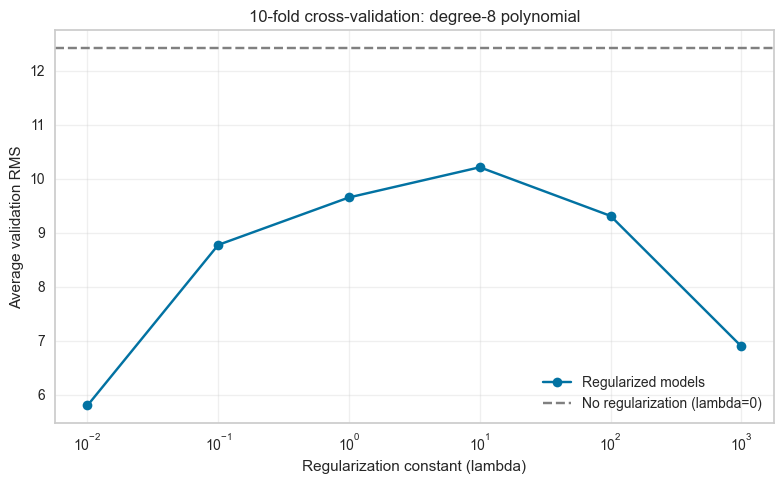

Best lambda: 0.01


In [15]:
#ten fold cross validation, split into 10 unique test sets

def polynomial_regression_reg(X, y, degree, reg):
    # Make the polynomial matrix and normalize using this fold's training data.
    Phi, x_means, x_scales = polynomial_design_matrix(X, degree)
    y_mean, y_scale = np.mean(y), np.std(y)
    if y_scale == 0:
        y_scale = 1.0
    y_scaled = (y - y_mean) / y_scale

    # L2 penalty on weights, excluding the bias weight at index 0.
    penalty = np.eye(Phi.shape[1])
    penalty[0, 0] = 0
    Phi_reg = np.vstack([Phi, np.sqrt(reg) * penalty])
    y_reg = np.concatenate([y_scaled, np.zeros(Phi.shape[1])])
    weights, *_ = np.linalg.lstsq(Phi_reg, y_reg, rcond=None)

    return {'weights': weights, 'x_means': x_means, 'x_scales': x_scales,
            'y_mean': y_mean, 'y_scale': y_scale, 'degree': degree}

# Use the second feature (ZN) from the first 100 training points.
X_d = X_train[:, 1]
reg_values = np.array([0, 0.01, 0.1, 1, 10, 100, 1000])
folds = np.array_split(np.random.default_rng(42).permutation(len(y_train)), 10)
validation_errors_d = []

for reg in reg_values:
    fold_errors = []

    for i in range(10):
        validation_indices = folds[i]
        training_indices = np.concatenate([folds[j] for j in range(10) if j != i])

        model_d = polynomial_regression_reg(
            X_d[training_indices], y_train[training_indices], degree=8, reg=reg)
        predictions = predict_polynomial_regression(
            model_d, X_d[validation_indices])
        fold_errors.append(rms_error(y_train[validation_indices], predictions))

    validation_errors_d.append(np.mean(fold_errors))

results_d = pd.DataFrame({
    'lambda': reg_values,
    'average_validation_RMS': validation_errors_d
})
display(results_d.round(3))

# Plot positive lambda values on a log x-axis; show lambda=0 as a baseline.
positive = reg_values > 0
plt.figure(figsize=(8, 5))
plt.semilogx(reg_values[positive], np.array(validation_errors_d)[positive],
             marker='o', label='Regularized models')
plt.axhline(validation_errors_d[0], color='gray', linestyle='--',
            label='No regularization (lambda=0)')
plt.xlabel('Regularization constant (lambda)')
plt.ylabel('Average validation RMS')
plt.title('10-fold cross-validation: degree-8 polynomial')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

best_index_d = np.argmin(validation_errors_d)
print(f'Best lambda: {reg_values[best_index_d]}')

# Q1 e

This uses all 13 input features. The Gaussian width is set to the median pairwise distance between standardized training rows because the assignment does not specify a width.

,number_of_basis_functions,training_RMS,test_RMS
0,5,3.546,13.335
1,15,2.158,9.087
2,25,1.630,7.489
3,35,1.354,7.427
4,45,1.233,10.208
5,55,1.113,9.860
6,65,1.082,13.142
7,75,0.910,7.780
8,85,0.677,102.701
9,95,0.424,197.635


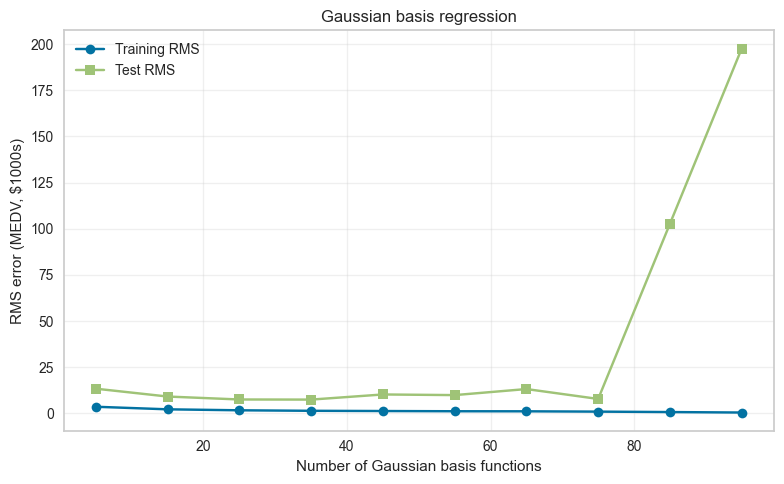

In [16]:
def gaussian_regression(X, y, num_basis, reg=0, center_indices=None, rng=None):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)

    # Normalize features using only this fit's training data.
    x_mean = X.mean(axis=0)
    x_scale = X.std(axis=0)
    x_scale = np.where(x_scale == 0, 1.0, x_scale)
    X_scaled = (X - x_mean) / x_scale

    # Pick Gaussian centers from the training rows.
    if center_indices is None:
        if rng is None:
            rng = np.random.default_rng()
        center_indices = rng.permutation(len(X))[:num_basis]
    else:
        center_indices = np.asarray(center_indices)[:num_basis]
    centers = X_scaled[center_indices]

    # Use the median pairwise training distance as the Gaussian width.
    pairwise = X_scaled[:, None, :] - X_scaled[None, :, :]
    pairwise_distances = np.sqrt(np.sum(pairwise ** 2, axis=2))
    upper_distances = pairwise_distances[np.triu_indices(len(X), k=1)]
    sigma = np.median(upper_distances[upper_distances > 0])
    if not np.isfinite(sigma) or sigma == 0:
        sigma = 1.0

    distances = X_scaled[:, None, :] - centers[None, :, :]
    distances_squared = np.sum(distances ** 2, axis=2)
    Phi = np.column_stack([
        np.ones(len(X)),
        np.exp(-distances_squared / (2 * sigma ** 2))
    ])

    # Normalize the target, then solve least squares (with optional L2 penalty).
    y_mean = y.mean()
    y_scale = y.std()
    if y_scale == 0:
        y_scale = 1.0
    y_scaled = (y - y_mean) / y_scale

    penalty = np.eye(Phi.shape[1])
    penalty[0, 0] = 0  # do not regularize the bias
    Phi_reg = np.vstack([Phi, np.sqrt(reg) * penalty])
    y_reg = np.concatenate([y_scaled, np.zeros(Phi.shape[1])])
    weights, *_ = np.linalg.lstsq(Phi_reg, y_reg, rcond=None)

    return {
        'weights': weights,
        'x_mean': x_mean,
        'x_scale': x_scale,
        'centers': centers,
        'sigma': sigma,
        'y_mean': y_mean,
        'y_scale': y_scale,
        'num_basis': num_basis
    }


def predict_gaussian_regression(model, X):
    X = np.asarray(X, dtype=float)
    x_scaled = (X - model['x_mean']) / model['x_scale']
    distances = x_scaled[:, None, :] - model['centers'][None, :, :]
    distances_squared = np.sum(distances ** 2, axis=2)
    Phi = np.column_stack([
        np.ones(len(X)),
        np.exp(-distances_squared / (2 * model['sigma'] ** 2))
    ])
    return (Phi @ model['weights']) * model['y_scale'] + model['y_mean']


# Use one random ordering so the centers for smaller K are contained in larger K.
basis_counts_e = np.arange(5, 100, 10)
rng_e = np.random.default_rng(42)
center_order_e = rng_e.permutation(len(y_train))
train_rms_e, test_rms_e, models_e = [], [], {}

for K in basis_counts_e:
    model_e = gaussian_regression(
        X_train, y_train, K, center_indices=center_order_e)
    models_e[K] = model_e
    train_rms_e.append(rms_error(
        y_train, predict_gaussian_regression(model_e, X_train)))
    test_rms_e.append(rms_error(
        y_test, predict_gaussian_regression(model_e, X_test)))

results_e = pd.DataFrame({
    'number_of_basis_functions': basis_counts_e,
    'training_RMS': train_rms_e,
    'test_RMS': test_rms_e
})
display(results_e.round(3))

plt.figure(figsize=(8, 5))
plt.plot(basis_counts_e, train_rms_e, marker='o', label='Training RMS')
plt.plot(basis_counts_e, test_rms_e, marker='s', label='Test RMS')
plt.xlabel('Number of Gaussian basis functions')
plt.ylabel('RMS error (MEDV, $1000s)')
plt.title('Gaussian basis regression')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Q1 f

This uses all 13 features and 90 Gaussian basis functions. Each fold fits its own normalization, Gaussian width, and centers using only that fold’s training rows.

,lambda,average_validation_RMS
0,0.00,9.218
1,0.01,1.815
2,0.10,2.045
3,1.00,2.562
4,10.00,3.192
5,100.00,4.352
6,1000.00,5.454


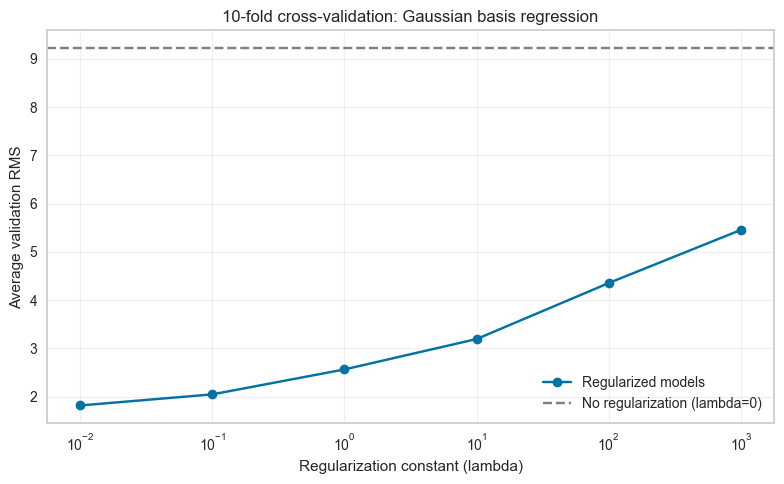

Best lambda: 0.01


In [17]:
# Ten-fold cross-validation for regularized Gaussian basis regression.
reg_values_f = np.array([0, 0.01, 0.1, 1, 10, 100, 1000])
folds_f = np.array_split(
    np.random.default_rng(42).permutation(len(y_train)), 10)
validation_rms_f = []

for reg in reg_values_f:
    fold_errors_f = []

    for i in range(10):
        validation_indices = folds_f[i]
        training_indices = np.concatenate(
            [folds_f[j] for j in range(10) if j != i])

        model_f = gaussian_regression(
            X_train[training_indices],
            y_train[training_indices],
            num_basis=90,
            reg=reg,
            rng=np.random.default_rng(100 + i)
        )
        predictions_f = predict_gaussian_regression(
            model_f, X_train[validation_indices])
        fold_errors_f.append(rms_error(
            y_train[validation_indices], predictions_f))

    validation_rms_f.append(np.mean(fold_errors_f))

results_f = pd.DataFrame({
    'lambda': reg_values_f,
    'average_validation_RMS': validation_rms_f
})
display(results_f.round(3))

# Zero cannot be shown on a log x-axis, so add it as a horizontal baseline.
positive_f = reg_values_f > 0
plt.figure(figsize=(8, 5))
plt.semilogx(reg_values_f[positive_f],
             np.array(validation_rms_f)[positive_f],
             marker='o', label='Regularized models')
plt.axhline(validation_rms_f[0], color='gray', linestyle='--',
            label='No regularization (lambda=0)')
plt.xlabel('Regularization constant (lambda)')
plt.ylabel('Average validation RMS')
plt.title('10-fold cross-validation: Gaussian basis regression')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

best_index_f = np.argmin(validation_rms_f)
print(f'Best lambda: {reg_values_f[best_index_f]}')